# Bank Campaign Predictor - AI Model

**Module:** Introduction to AI (AIN5301EN)

In this notebook I build the AI part of my MVP. The goal is to predict if a bank customer will say **yes** to a term deposit
campaign, so the bank can call the customers that are more likely to accept.

Type of problem: **Classification** (yes / no)

Dataset: Bank Marketing dataset (Kaggle / UCI) - `bank-additional-full.csv`

## 1. Import libraries

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

# all the charts are saved in this folder, so I can use them in the report
os.makedirs("figures", exist_ok=True)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

## 2. Load the data into a database

For the MVP I use a small **SQLite** database (`bank.db`). First I load the CSV file into a table called `customers`.
After that, the model reads the data from the database and not from the CSV directly. The web app also uses the same database.

In [2]:
df_csv = pd.read_csv("data/bank-additional-full.csv", sep=";")

# the dot in some column names is annoying in SQL, so I replace it with _
df_csv.columns = [c.replace(".", "_") for c in df_csv.columns]

conn = sqlite3.connect("bank.db")
df_csv.to_sql("customers", conn, if_exists="replace", index=False)

df = pd.read_sql("SELECT * FROM customers", conn)
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Explore the data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 non-null  float64
 1

In [4]:
print(df.isnull().sum().sum(), "missing values")
df["y"].value_counts()

0 missing values


y
no     36548
yes     4640
Name: count, dtype: int64

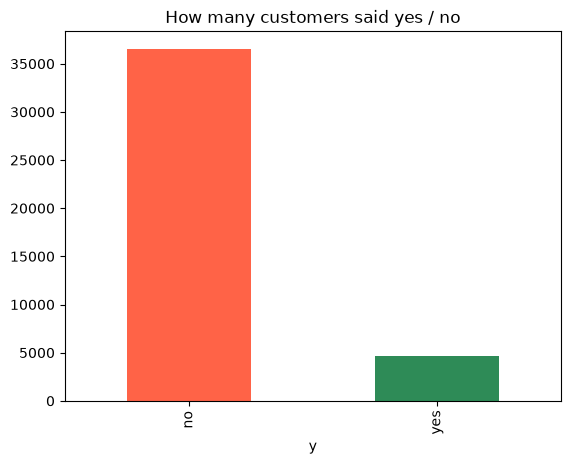

In [5]:
df["y"].value_counts().plot(kind="bar", color=["tomato", "seagreen"])
plt.title("How many customers said yes / no")
plt.savefig("figures/01_yes_no_count.png", dpi=150, bbox_inches="tight")
plt.show()

The data is **imbalanced**: about 89% of customers said "no" and only 11% said "yes".
This means that accuracy alone is not a good measure, because a model that always says "no" would get 89% accuracy.
I will also look at recall and F1 score.

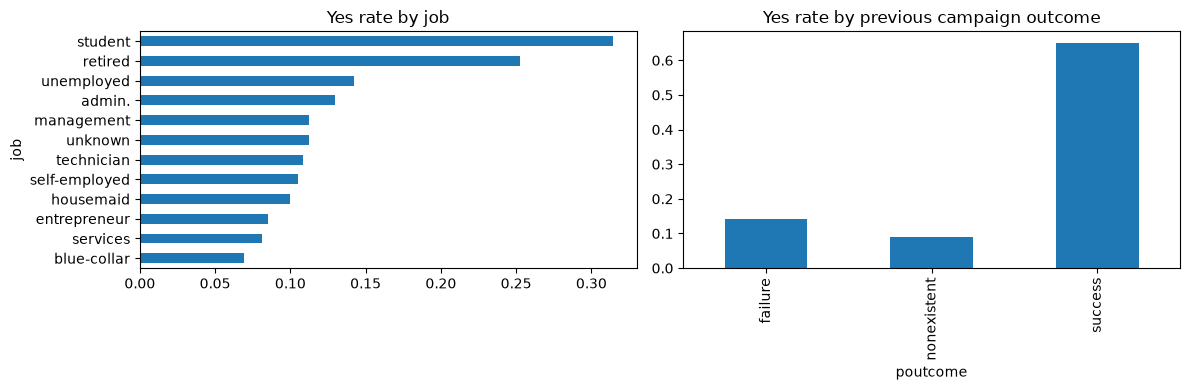

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(df.groupby("job")["y"].apply(lambda s: (s == "yes").mean()).sort_values()
   .plot(kind="barh", ax=axes[0], title="Yes rate by job"))
(df.groupby("poutcome")["y"].apply(lambda s: (s == "yes").mean())
   .plot(kind="bar", ax=axes[1], title="Yes rate by previous campaign outcome"))
plt.tight_layout()
plt.savefig("figures/02_yes_rate_job_poutcome.png", dpi=150, bbox_inches="tight")
plt.show()

Students and retired people say yes more often. Also customers where the **previous campaign was a success** say yes much more.
These patterns are not easy to write as simple if/else rules, which is why I use a machine learning model.

## 4. Preprocessing

Decisions:
- I **remove `duration`** (length of the last call). The dataset documentation says this column should be removed for a realistic model,
  because we only know the duration after the call is finished. If I keep it, the model "cheats".
- I also remove the economic columns (`emp_var_rate`, `cons_price_idx`, `cons_conf_idx`, `euribor3m`, `nr_employed`)
  because a bank employee using my app would not type these values. This keeps the MVP simple (see limitations).
- `pdays = 999` means the customer was never contacted before. I make a new column `contacted_before` (0/1).
- Categorical columns -> **One Hot Encoding**, numeric columns -> **StandardScaler**.
- Target: yes = 1, no = 0.

In [7]:
drop_cols = ["duration", "emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"]
data = df.drop(columns=drop_cols)

data["contacted_before"] = (data["pdays"] != 999).astype(int)
data = data.drop(columns=["pdays"])

X = data.drop(columns=["y"])
y = (data["y"] == "yes").astype(int)

cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
num_cols = ["age", "campaign", "previous", "contacted_before"]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (32950, 14)  Test: (8238, 14)


## 5. Train and compare models

I try 3 classification algorithms:
1. **Logistic Regression** - simple, fast, easy to explain
2. **Decision Tree** - easy to understand (if/else tree learned from data)
3. **Random Forest** - many decision trees together, usually more accurate

Because the data is imbalanced I use `class_weight="balanced"`, so the model pays more attention to the "yes" customers.

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=42, n_jobs=-1),
}

results = []
pipelines = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    pipelines[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).round(3)
results_df.to_csv("figures/model_results.csv", index=False)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.797,0.297,0.587,0.394,0.765
1,Decision Tree,0.870,0.422,0.412,0.417,0.728
2,Random Forest,0.840,0.365,0.577,0.447,0.782


### Baseline
For comparison, a "dummy" model that always predicts "no":

In [9]:
dummy_pred = np.zeros(len(y_test))
print("Accuracy:", round(accuracy_score(y_test, dummy_pred), 3))
print("Recall:  ", recall_score(y_test, dummy_pred))

Accuracy: 0.887
Recall:   0.0


The dummy model has high accuracy but recall 0 - it never finds a single customer who says yes. So it is useless for the bank.
My models have lower accuracy, but they actually find most of the "yes" customers.

## 6. Evaluation of the best model

Best model: Random Forest
              precision    recall  f1-score   support

          no       0.94      0.87      0.91      7310
         yes       0.37      0.58      0.45       928

    accuracy                           0.84      8238
   macro avg       0.65      0.72      0.68      8238
weighted avg       0.88      0.84      0.85      8238



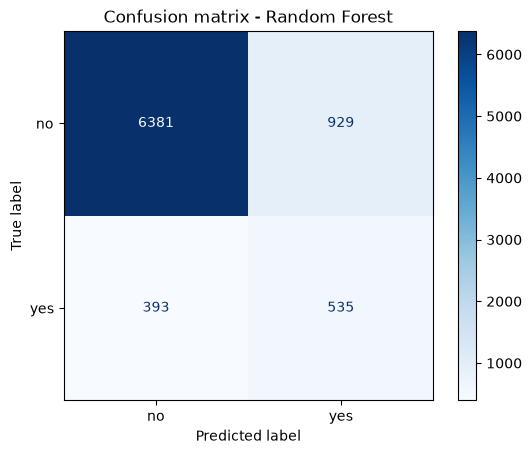

In [10]:
best_name = results_df.sort_values("ROC AUC", ascending=False).iloc[0]["Model"]
best = pipelines[best_name]
print("Best model:", best_name)

pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=["no", "yes"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["no", "yes"]).plot(cmap="Blues")
plt.title("Confusion matrix - " + best_name)
plt.savefig("figures/03_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### Which features are most important?

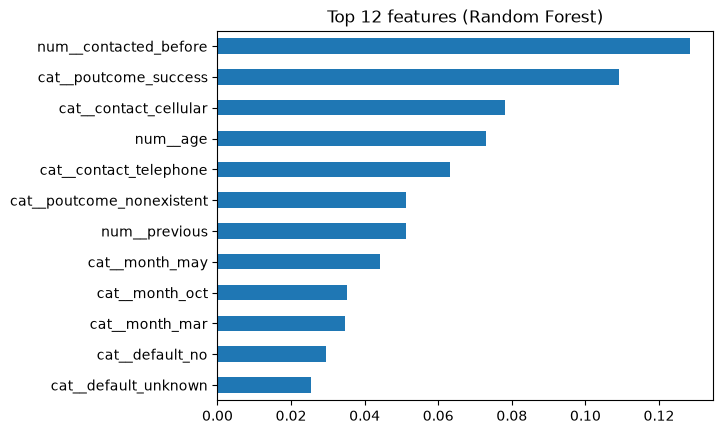

In [11]:
rf = pipelines["Random Forest"]
feature_names = rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names)
importances.sort_values().tail(12).plot(kind="barh")
plt.title("Top 12 features (Random Forest)")
plt.savefig("figures/04_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

### Performance (speed)

In [12]:
import time
start = time.time()
best.predict(X_test)
total = time.time() - start
print(f"Predicting {len(X_test)} customers took {total:.3f} seconds")
print(f"About {total / len(X_test) * 1000:.4f} ms per customer")

Predicting 8238 customers took 0.076 seconds
About 0.0092 ms per customer


## 7. Example inputs and outputs

In [13]:
examples = pd.DataFrame([
    {"age": 30, "job": "student", "marital": "single", "education": "university.degree", "default": "no",
     "housing": "no", "loan": "no", "contact": "cellular", "month": "oct", "day_of_week": "tue",
     "campaign": 1, "previous": 1, "poutcome": "success", "contacted_before": 1},
    {"age": 45, "job": "blue-collar", "marital": "married", "education": "basic.9y", "default": "unknown",
     "housing": "yes", "loan": "yes", "contact": "telephone", "month": "may", "day_of_week": "mon",
     "campaign": 6, "previous": 0, "poutcome": "nonexistent", "contacted_before": 0},
])
examples["probability_yes"] = best.predict_proba(examples)[:, 1].round(2)
examples["prediction"] = np.where(examples["probability_yes"] >= 0.5, "yes", "no")
examples[["age", "job", "poutcome", "campaign", "probability_yes", "prediction"]]

,age,job,poutcome,campaign,probability_yes,prediction
0,30,student,success,1,0.93,yes
1,45,blue-collar,nonexistent,6,0.22,no


## 8. Save the model
The web app loads this file to make predictions.

In [14]:
joblib.dump(best, "model.pkl", compress=3)
conn.close()
print("Saved model.pkl")

Saved model.pkl
